---
# <div align="center"><font color='blue'> COSC 2779/2972 | Deep Learning </font></div>
## <div align="center"><font color='blue'> Week 9 Lab: Solving Problems with Foundation Models</font></div>
---

Modern AI systems are rarely trained from scratch. Practitioners start with powerful pretrained models and adapt them — balancing compute, data, performance, and deployment constraints.

This lab brings together everything from Weeks 3–8 into a unified framework. You've already done transfer learning for vision (Week 5) and NLP (Week 8). This week, we formalise the **decision process** and add a new tool: **parameter-efficient fine-tuning (PEFT)**.

We focus on NLP using the HappyDB task from Weeks 7–8, so you can directly compare all approaches.

## 🎯 Learning Objectives

By the end of this lab, you should be able to:

- Explain what foundation models are and why they dominate modern AI
- Compare adaptation strategies: zero-shot, feature extraction, fine-tuning, and PEFT
- Implement each strategy on the same task and compare results
- Apply parameter-efficient fine-tuning (LoRA) in practice using the `peft` library
- Make practical engineering decisions about how to adapt a foundation model
- Analyse failure cases and biases in foundation models

**Prerequisites:** Weeks 3–8 (CNNs, transfer learning, RNNs, transformers)

**Duration:** ~2–3 hours

---

## What Is a Foundation Model?

A **foundation model** is a large model pretrained on massive, broad data that can be adapted to many downstream tasks (Bommasani et al., Stanford HAI, 2021).

| Domain | Examples | Pretrained On |
|---|---|---|
| NLP | BERT, GPT, T5, LLaMA | Web text, books, Wikipedia |
| Vision | ResNet, ViT, DINOv2 | ImageNet, web images |
| Multimodal | CLIP, Flamingo, GPT-4V | Image-text pairs from the web |

## Setup

In [1]:
# ============================================
# Run this cell FIRST, then restart the runtime
# (Runtime → Restart runtime), then continue
# from the next cell onwards
# ============================================
!pip install -q "transformers==4.51.3" "peft==0.14.0" "huggingface_hub==0.30.2" datasets

In [1]:
!pip install -q transformers datasets peft

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from collections import Counter
import os, warnings

os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
warnings.filterwarnings('ignore', message='.*HF_TOKEN.*')
warnings.filterwarnings('ignore', message='.*unauthenticated.*')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### Training Utilities

In [2]:
def train_one_epoch_hf(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        y = batch['labels'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        _, predicted = torch.max(logits, 1)
        correct += (predicted == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total


def evaluate_hf(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.inference_mode():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            y = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            loss = criterion(logits, y)
            total_loss += loss.item() * y.size(0)
            _, predicted = torch.max(logits, 1)
            correct += (predicted == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total


def run_experiment_hf(model, optimizer, criterion, train_loader, val_loader,
                      epochs=5, name='Model'):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        tl, ta = train_one_epoch_hf(model, train_loader, optimizer, criterion)
        vl, va = evaluate_hf(model, val_loader, criterion)
        history['train_loss'].append(tl)
        history['train_acc'].append(ta)
        history['val_loss'].append(vl)
        history['val_acc'].append(va)
        if (epoch + 1) % max(1, epochs // 3) == 0 or epoch == 0:
            print(f'  [{name}] Epoch {epoch+1}/{epochs} — '
                  f'Train: {tl:.4f}/{ta:.4f} | Val: {vl:.4f}/{va:.4f}')
    return history


def plot_experiments(results, show_train=True, show_val=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name, hist in results.items():
        epochs = range(1, len(hist['train_loss']) + 1)
        if show_train:
            axes[0].plot(epochs, hist['train_loss'], label=f'{name} (T)', marker='o', markersize=3)
            axes[1].plot(epochs, hist['train_acc'], label=f'{name} (T)', marker='o', markersize=3)
        if show_val:
            axes[0].plot(epochs, hist['val_loss'], label=f'{name} (V)', linestyle='--', marker='x', markersize=3)
            axes[1].plot(epochs, hist['val_acc'], label=f'{name} (V)', linestyle='--', marker='x', markersize=3)
    for ax, ylabel in zip(axes, ['Loss', 'Accuracy']):
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(ylabel)
        ax.legend(fontsize=7); ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'  Trainable: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')
    return trainable, total

## Load HappyDB (same task as Weeks 7–8)

In [3]:
!wget -q https://raw.githubusercontent.com/megagonlabs/HappyDB/master/happydb/data/cleaned_hm.csv

df = pd.read_csv('cleaned_hm.csv').dropna(subset=['predicted_category', 'cleaned_hm'])
label_names = sorted(df['predicted_category'].unique())
label_to_idx = {l: i for i, l in enumerate(label_names)}
NUM_CLASSES = len(label_names)

texts = df['cleaned_hm'].tolist()
labels = [label_to_idx[c] for c in df['predicted_category']]

# Subsample
SUBSET = 10000
texts, _, labels, _ = train_test_split(texts, labels, train_size=SUBSET, random_state=42, stratify=labels)
X_temp, X_test, y_temp, y_test = train_test_split(texts, labels, test_size=0.15, random_state=42, stratify=labels)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp)

print(f'Classes ({NUM_CLASSES}): {label_names}')
print(f'Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}')

Classes (7): ['achievement', 'affection', 'bonding', 'enjoy_the_moment', 'exercise', 'leisure', 'nature']
Train: 7004, Val: 1496, Test: 1500


In [4]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

class HFDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=64):
        self.labels = labels
        self.encodings = tokenizer(texts, padding='max_length', truncation=True,
                                   max_length=max_length, return_tensors='pt')
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }

hf_train = HFDataset(X_train, y_train, tokenizer)
hf_val = HFDataset(X_val, y_val, tokenizer)
hf_test = HFDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(hf_train, batch_size=32, shuffle=True)
val_loader = DataLoader(hf_val, batch_size=64, shuffle=False)
test_loader = DataLoader(hf_test, batch_size=64, shuffle=False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


In [5]:
# Class weights for imbalanced data
class_counts = Counter(y_train)
total = sum(class_counts.values())
class_weights = torch.tensor([total / class_counts[i] for i in range(NUM_CLASSES)], dtype=torch.float32).to(device)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES
criterion = nn.CrossEntropyLoss(weight=class_weights)

---
# Part 1: Adaptation Strategies — The Decision Framework 

| Strategy | What You Train | Trainable % | Data Needed | Best When |
|---|---|---|---|---|
| **Zero-shot** | Nothing | 0% | None | Quick prototyping, no labels |
| **Feature extraction** | Small classifier | ~0.01% | Small (100s) | Limited data/compute |
| **Linear probing** | Classifier head | ~0.1% | Small (1000s) | Fast baseline |
| **Partial fine-tuning** | Top layers + head | ~10% | Moderate (1000s) | Some domain gap |
| **Full fine-tuning** | All parameters | 100% | Large (10000s+) | Large domain gap |
| **PEFT (LoRA)** | Small inserted matrices | ~0.5–2% | Small–moderate | Large models, limited compute |

We'll implement **each of these** on HappyDB and compare the results.

### 🤔 Questions

1. Why is training from scratch rarely done in practice anymore?
2. What are the risks of full fine-tuning on a small dataset?
3. When might zero-shot be sufficient — and when would it clearly fail?

*Double-click here to write your answers...*

---
# Part 2: Zero-Shot Classification

The most extreme adaptation: use a pretrained model **directly** with no task-specific training. The model has never seen HappyDB, yet attempts classification by leveraging its understanding of language.

We use Hugging Face's `zero-shot-classification` pipeline, which uses a model trained on natural language inference (NLI) to match text to candidate labels.

In [6]:
from transformers import pipeline

zero_shot = pipeline(
    'zero-shot-classification',
    model='facebook/bart-large-mnli',
    device=0 if torch.cuda.is_available() else -1
)

# Quick test
test_texts = [
    "I had a wonderful dinner with my family tonight",
    "I ran five miles at the gym this morning",
    "I got a promotion at work today",
    "I enjoyed a beautiful sunset at the park",
    "My friends came over for a game night",
]

for text in test_texts:
    result = zero_shot(text, candidate_labels=label_names)
    print(f'  "{text[:55]}..." → {result["labels"][0]} ({result["scores"][0]:.0%})\n')

Device set to use cuda:0


  "I had a wonderful dinner with my family tonight..." → bonding (44%)

  "I ran five miles at the gym this morning..." → exercise (85%)

  "I got a promotion at work today..." → achievement (87%)

  "I enjoyed a beautiful sunset at the park..." → leisure (25%)

  "My friends came over for a game night..." → bonding (60%)



In [7]:
# Evaluate on a sample (slow — limit to 200)
n_eval = min(200, len(X_val))
zs_preds = []
print(f'Evaluating zero-shot on {n_eval} samples...')
for i in range(n_eval):
    result = zero_shot(X_val[i], candidate_labels=label_names)
    zs_preds.append(label_to_idx[result['labels'][0]])
    if (i + 1) % 50 == 0: print(f'  {i+1}/{n_eval}')

zs_acc = np.mean(np.array(zs_preds) == np.array(y_val[:n_eval]))
print(f'\nZero-shot accuracy: {zs_acc:.4f}')
print('Trainable parameters: 0')

Evaluating zero-shot on 200 samples...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  50/200
  100/200
  150/200
  200/200

Zero-shot accuracy: 0.4900
Trainable parameters: 0


### 🤔 Questions

1. How does zero-shot accuracy compare to the trained models from Weeks 7–8?
2. What kinds of examples does zero-shot get wrong?
3. When would zero-shot be "good enough" in a real project?

*Double-click here to write your answers...*

---
# Part 3: Feature Extraction with Frozen Embeddings 

Instead of fine-tuning DistilBERT, we extract its embeddings once and train a simple classifier (logistic regression) on top. The transformer is **never updated** — it's a frozen feature extractor.

This is the fastest and cheapest strategy that uses task-specific labels.

In [8]:
from transformers import AutoModel

feat_model = AutoModel.from_pretrained('distilbert-base-uncased', token=False).to(device)
feat_model.eval()

def extract_embeddings(texts, tokenizer, model, batch_size=64):
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, padding=True, truncation=True,
                           max_length=64, return_tensors='pt').to(device)
        with torch.inference_mode():
            outputs = model(**encoded)
        # [CLS] token embedding
        all_embs.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    return np.vstack(all_embs)

print('Extracting embeddings...')
train_embs = extract_embeddings(X_train, tokenizer, feat_model)
val_embs = extract_embeddings(X_val, tokenizer, feat_model)
print(f'Shape: {train_embs.shape}')

Extracting embeddings...
Shape: (7004, 768)


In [9]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(max_iter=1000, C=1.0)
lr_clf.fit(train_embs, y_train)

fe_train_acc = accuracy_score(y_train, lr_clf.predict(train_embs))
fe_val_acc = accuracy_score(y_val, lr_clf.predict(val_embs))

print(f'Feature Extraction + LogReg:')
print(f'  Train: {fe_train_acc:.4f}')
print(f'  Val:   {fe_val_acc:.4f}')
print(f'  Trainable: ~{768 * NUM_CLASSES} (sklearn weights only)')

Feature Extraction + LogReg:
  Train: 0.8842
  Val:   0.8068
  Trainable: ~5376 (sklearn weights only)


### 🤔 Questions 

1. How does feature extraction compare to zero-shot?
2. What are the advantages of this approach? (speed, memory, simplicity)
3. Why do DistilBERT's embeddings transfer well to a task it was never trained for?

*Double-click here to write your answers...*

---
# Part 4: Fine-Tuning Strategies Compared

Now let's compare the three fine-tuning strategies using DistilBERT:

1. **Linear probing** — freeze backbone, train only the classification head
2. **Partial fine-tuning** — unfreeze the last transformer layer + head
3. **Full fine-tuning** — all parameters trainable

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



--- Linear Probing ---
  pre_classifier.weight: torch.Size([768, 768])
  pre_classifier.bias: torch.Size([768])
  classifier.weight: torch.Size([7, 768])
  classifier.bias: torch.Size([7])
  Trainable: 595,975 / 66,958,855 (0.89%)
  [classifier.bias] Epoch 1/10 — Train: 1.3035/0.5481 | Val: 0.9116/0.7106
  [classifier.bias] Epoch 3/10 — Train: 0.7972/0.7072 | Val: 0.7403/0.7353
  [classifier.bias] Epoch 6/10 — Train: 0.6781/0.7312 | Val: 0.7443/0.7533
  [classifier.bias] Epoch 9/10 — Train: 0.6265/0.7490 | Val: 0.6594/0.7540


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



--- Partial FT (last lyr) ---
  Trainable: 7,683,847 / 66,958,855 (11.48%)
  [Partial FT (last lyr)] Epoch 1/5 — Train: 1.1475/0.6192 | Val: 0.5632/0.8229
  [Partial FT (last lyr)] Epoch 2/5 — Train: 0.5045/0.8137 | Val: 0.4665/0.8409
  [Partial FT (last lyr)] Epoch 3/5 — Train: 0.4232/0.8392 | Val: 0.4547/0.8409
  [Partial FT (last lyr)] Epoch 4/5 — Train: 0.3645/0.8541 | Val: 0.4406/0.8630
  [Partial FT (last lyr)] Epoch 5/5 — Train: 0.3067/0.8712 | Val: 0.4721/0.8616


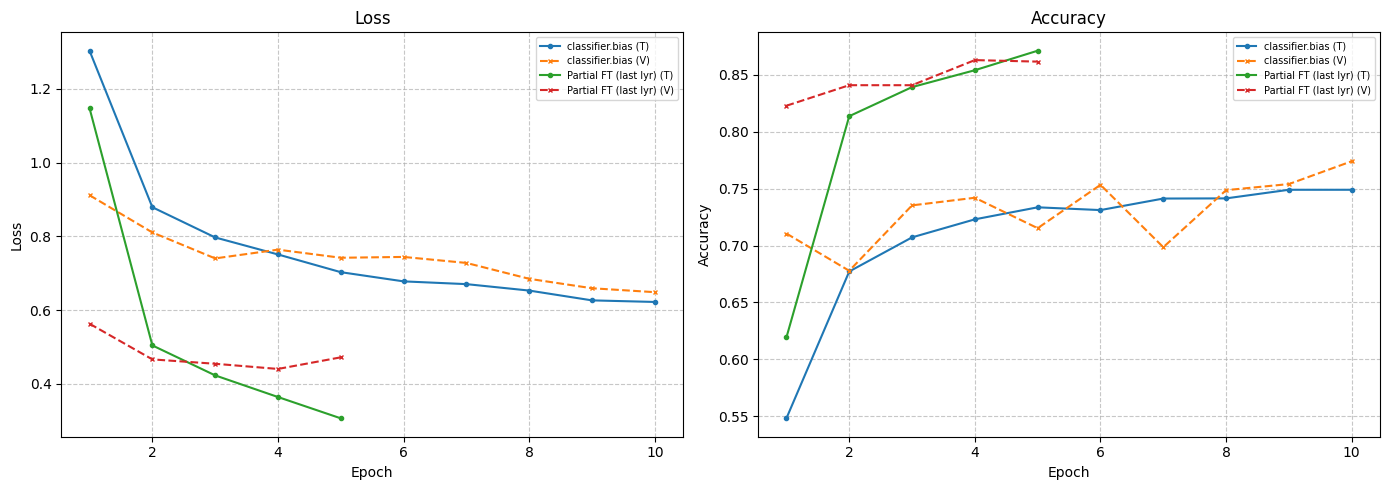

In [10]:
from transformers import AutoModelForSequenceClassification

all_results = {}

strategies = {
    'Linear Probing':       {'freeze': 'all',     'lr': 1e-3, 'epochs': 10},
    'Partial FT (last lyr)': {'freeze': 'partial', 'lr': 5e-5, 'epochs': 5},
    # 'Full Fine-Tuning':     {'freeze': 'none',    'lr': 2e-5, 'epochs': 3}, #uncomment if you have time
}

for name, cfg in strategies.items():
    print(f'\n--- {name} ---')
    torch.manual_seed(0)
    model = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=NUM_CLASSES, token=False
    ).to(device)
    
    if cfg['freeze'] == 'all':
        for param in model.distilbert.parameters():
            param.requires_grad = False
            
        # After freezing, check which parameters are trainable
        for name, param in model.named_parameters():
            if param.requires_grad:
                print(f'  {name}: {param.shape}')
                
    elif cfg['freeze'] == 'partial':
        for param in model.distilbert.parameters():
            param.requires_grad = False
        for param in model.distilbert.transformer.layer[-1].parameters():
            param.requires_grad = True
    
    count_params(model)
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg['lr'], weight_decay=0.01
    )
    all_results[name] = run_experiment_hf(
        model, optimizer, criterion, train_loader, val_loader,
        epochs=cfg['epochs'], name=name
    )

plot_experiments(all_results)

👉 Why does Feature Extraction + LogReg outperform Linear Probing? This may seem counterintuitive — both use frozen DistilBERT features. The difference is in the classifier:

- Feature Extraction + LogReg: sklearn's logistic regression solves a convex optimisation problem — it finds the global optimum every time.

- Linear Probing (HF head): DistilBERT's classification head includes a pre_classifier layer (768→768 dense + ReLU) before the final linear layer. This makes the optimisation non-convex, and the randomly initialised pre-classifier needs more careful tuning to converge.

This is a useful practical lesson: sometimes a simpler model with a better optimizer beats a more complex model that's harder to train.

👉 Try changing the last classifier head to a single layer NN and see if it improves the results for Linear Probing. 

### 🤔 Questions

1. Rank the strategies by validation accuracy. Does the ranking match the amount of training?
2. Is the gap between linear probing and full fine-tuning large or small? What does this tell you about DistilBERT's pretrained features?
3. When would you choose linear probing over full fine-tuning in practice?

*Double-click here to write your answers...*

---
# Part 5: Parameter-Efficient Fine-Tuning — LoRA 

## The Problem with Full Fine-Tuning

As models grow larger, full fine-tuning becomes impractical:

| Model | Parameters | GPU Memory (Full FT) |
|---|---|---|
| DistilBERT | 66M | ~2 GB |
| BERT-Large | 340M | ~8 GB |
| LLaMA-7B | 7B | ~28 GB |
| LLaMA-70B | 70B | ~280 GB |

**PEFT methods** solve this by training only a small number of additional parameters while keeping the foundation model frozen.

## LoRA: Low-Rank Adaptation

LoRA (Hu et al., 2022) is the most widely used PEFT method. The key insight: the weight updates during fine-tuning are **low-rank** — they can be approximated by much smaller matrices.

Instead of updating a weight matrix $W \in \mathbb{R}^{d \times d}$ directly, LoRA learns a low-rank decomposition:

$$W' = W + \Delta W = W + BA$$

where $B \in \mathbb{R}^{d \times r}$ and $A \in \mathbb{R}^{r \times d}$, with rank $r \ll d$ (typically $r = 4, 8, 16$).

- The original weight $W$ is **frozen** (no gradients, no optimizer state)
- Only $B$ and $A$ are trained — typically **< 1%** of the original parameters
- At inference, $BA$ can be **merged** into $W$ — zero additional latency

### Why Does This Work?

Research has shown that the weight updates $\Delta W$ during fine-tuning typically have a much lower intrinsic rank than the full weight matrices. In other words, fine-tuning doesn't need to change all directions in parameter space — only a small subspace matters. LoRA explicitly parameterises this subspace.

### How LoRA Works (Visual)

```
Original:  x → [  W  ] → y         (d×d parameters, all frozen)

With LoRA: x → [  W  ] → y₁        (frozen)
           x → [ A ][ B ] → y₂      (r×d + d×r trainable, r << d)
           y = y₁ + y₂              (sum the outputs)
```

For DistilBERT with $d = 768$ and $r = 8$:
- Original matrix: $768 \times 768 = 589,824$ parameters
- LoRA matrices: $768 \times 8 + 8 \times 768 = 12,288$ parameters (**2% of original**)

### Task 5.1 — Apply LoRA to DistilBERT

In [11]:
from peft import LoraConfig, get_peft_model, TaskType

# Load a fresh DistilBERT
torch.manual_seed(0)
base_model = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=NUM_CLASSES, token=False
).to(device)

# Define LoRA configuration
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,   # sequence classification
    r=8,                           # rank of the low-rank matrices
    lora_alpha=16,                 # scaling factor
    lora_dropout=0.1,              # dropout on LoRA layers
    target_modules=['q_lin', 'v_lin'],  # apply LoRA to attention Q and V matrices
)

# Wrap the model with LoRA
lora_model = get_peft_model(base_model, lora_config)

# Show what changed
lora_model.print_trainable_parameters()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 743,431 || all params: 67,702,286 || trainable%: 1.0981


👉 **Key observation:** Only ~0.5–2% of parameters are trainable. The entire DistilBERT backbone is frozen — only the tiny LoRA matrices ($A$ and $B$) and the classification head are updated.

The `target_modules=['q_lin', 'v_lin']` tells LoRA to apply low-rank updates to the **Query** and **Value** projection matrices in the self-attention layers. These are the matrices where fine-tuning has the most impact, according to the LoRA paper.

  [LoRA r=8] Epoch 1/5 — Train: 1.2846/0.5955 | Val: 0.6597/0.7868
  [LoRA r=8] Epoch 2/5 — Train: 0.5672/0.7970 | Val: 0.5367/0.8135
  [LoRA r=8] Epoch 3/5 — Train: 0.4675/0.8162 | Val: 0.5242/0.8422
  [LoRA r=8] Epoch 4/5 — Train: 0.4272/0.8320 | Val: 0.4952/0.8416
  [LoRA r=8] Epoch 5/5 — Train: 0.3952/0.8392 | Val: 0.4688/0.8422


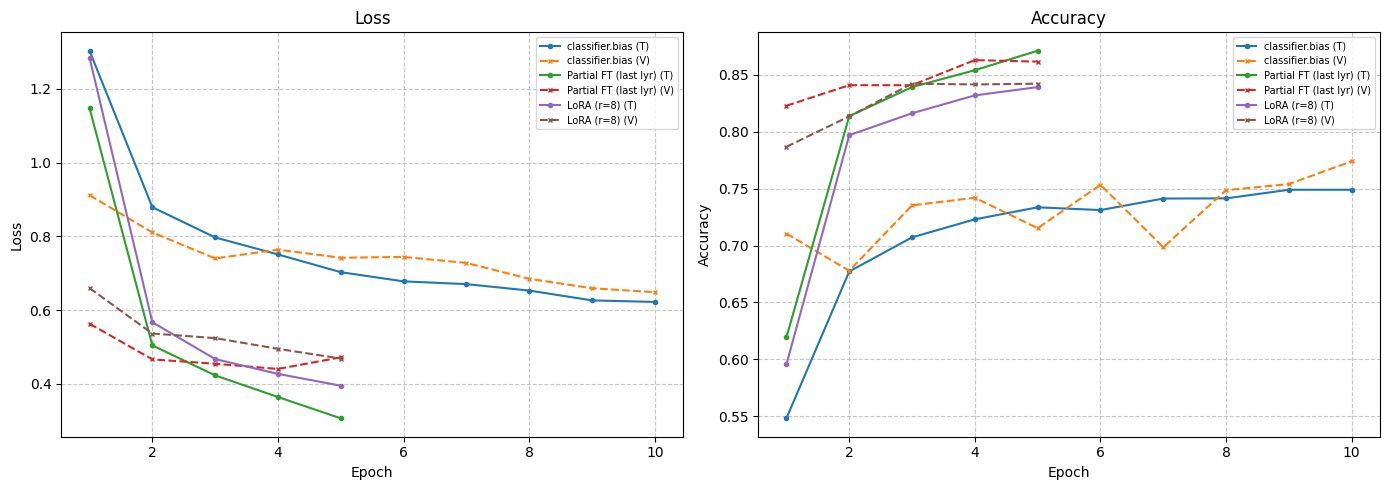

In [12]:
# Train the LoRA model
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, lora_model.parameters()),
                        lr=1e-4, weight_decay=0.01)

all_results['LoRA (r=8)'] = run_experiment_hf(
    lora_model, optimizer, criterion, train_loader, val_loader,
    epochs=5, name='LoRA r=8'
)

plot_experiments(all_results)

### Task 5.2 — Compare LoRA Ranks

You may skip this if the time is limited. get back to this as a hoework. 

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



--- LoRA r=2 ---
trainable params: 632,839 || all params: 67,591,694 || trainable%: 0.9363
  [LoRA r=2] Epoch 1/5 — Train: 1.4820/0.5196 | Val: 0.7667/0.7360
  [LoRA r=2] Epoch 2/5 — Train: 0.6431/0.7746 | Val: 0.5950/0.7781
  [LoRA r=2] Epoch 3/5 — Train: 0.5284/0.8060 | Val: 0.5550/0.8115
  [LoRA r=2] Epoch 4/5 — Train: 0.4701/0.8207 | Val: 0.5040/0.8275


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [LoRA r=2] Epoch 5/5 — Train: 0.4386/0.8258 | Val: 0.4975/0.8282

--- LoRA r=8 ---
trainable params: 743,431 || all params: 67,702,286 || trainable%: 1.0981
  [LoRA r=8] Epoch 1/5 — Train: 1.2846/0.5955 | Val: 0.6597/0.7868
  [LoRA r=8] Epoch 2/5 — Train: 0.5672/0.7970 | Val: 0.5367/0.8135
  [LoRA r=8] Epoch 3/5 — Train: 0.4675/0.8162 | Val: 0.5242/0.8422
  [LoRA r=8] Epoch 4/5 — Train: 0.4272/0.8320 | Val: 0.4952/0.8416


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [LoRA r=8] Epoch 5/5 — Train: 0.3952/0.8392 | Val: 0.4688/0.8422

--- LoRA r=32 ---
trainable params: 1,185,799 || all params: 68,144,654 || trainable%: 1.7401
  [LoRA r=32] Epoch 1/5 — Train: 1.1424/0.6235 | Val: 0.6278/0.8008
  [LoRA r=32] Epoch 2/5 — Train: 0.5294/0.8142 | Val: 0.5285/0.8356
  [LoRA r=32] Epoch 3/5 — Train: 0.4468/0.8291 | Val: 0.4969/0.8529
  [LoRA r=32] Epoch 4/5 — Train: 0.3826/0.8481 | Val: 0.4911/0.8583
  [LoRA r=32] Epoch 5/5 — Train: 0.3577/0.8529 | Val: 0.4959/0.8489


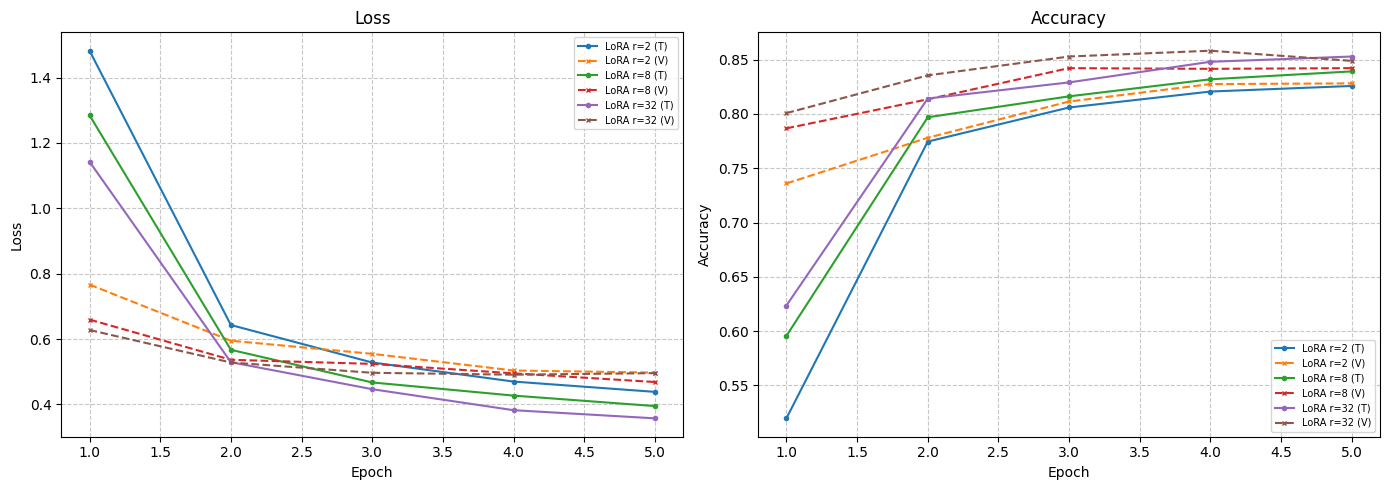

In [16]:
# How does the rank (r) affect performance?
lora_rank_results = {}

for r in [2, 8, 32]:
    print(f'\n--- LoRA r={r} ---')
    torch.manual_seed(0)
    base = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=NUM_CLASSES, token=False
    ).to(device)
    
    config = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=r, lora_alpha=r*2,
        lora_dropout=0.1, target_modules=['q_lin', 'v_lin'],
    )
    peft_model = get_peft_model(base, config)
    peft_model.print_trainable_parameters()
    
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()),
                            lr=1e-4, weight_decay=0.01)
    lora_rank_results[f'LoRA r={r}'] = run_experiment_hf(
        peft_model, optimizer, criterion, train_loader, val_loader,
        epochs=5, name=f'LoRA r={r}'
    )

plot_experiments(lora_rank_results)

### Other PEFT Methods (Conceptual)

LoRA is the most popular, but there are other approaches:

| Method | Idea | Trainable Params | Inference Cost |
|---|---|---|---|
| **LoRA** | Low-rank updates to weight matrices | ~0.5–2% | Zero (merge into weights) |
| **Adapters** | Small bottleneck layers inserted between transformer layers | ~2–5% | Small overhead per layer |
| **Prompt Tuning** | Learn soft prompt embeddings prepended to input | <0.1% | Zero extra params at inference |
| **Prefix Tuning** | Learn key/value prefixes for attention layers | ~0.1–1% | Small overhead |

LoRA's key advantage: **zero inference overhead** after merging. Adapters and prefix tuning add small but permanent overhead.

### 🤔 Questions 

1. How does LoRA's validation accuracy compare to full fine-tuning? How many fewer parameters does it train?
2. Does increasing the rank ($r$) always improve performance? What are the diminishing returns?
3. Why does LoRA target the attention Q and V matrices specifically?
4. Why is PEFT becoming increasingly important as models grow larger?
5. What is the practical advantage of LoRA over adapters? (Hint: inference time.)

*Double-click here to write your answers...*

---
# Part 6: The Full Comparison 

Let's bring together every strategy we've tested on the same task.

In [13]:
print(f'{"Strategy":<30} {"Val Acc":<12} {"Trainable Params"}')
print('=' * 65)
print(f'{"Zero-shot":<30} {zs_acc:<12.4f} {"0"}')
print(f'{"Feature Extract + LogReg":<30} {fe_val_acc:<12.4f} {"~5,376 (sklearn)"}')
for name, hist in all_results.items():
    print(f'{name:<30} {max(hist["val_acc"]):<12.4f}')

Strategy                       Val Acc      Trainable Params
Zero-shot                      0.4900       0
Feature Extract + LogReg       0.8068       ~5,376 (sklearn)
classifier.bias                0.7741      
Partial FT (last lyr)          0.8630      
LoRA (r=8)                     0.8422      


### 🤔 Questions 

1. What is the accuracy-per-trainable-parameter efficiency of each strategy?
2. Is there a clear "winner"? Or does the best choice depend on constraints?
3. If you had to deploy a model tomorrow with minimal compute, which strategy would you choose?

*Double-click here to write your answers...*

---
# Part 7: Choosing the Right Strategy — Scenario Reasoning 

For each scenario, choose an adaptation strategy and justify your reasoning.

### Scenario A
**Task:** Classify X-ray images as normal vs pneumonia.
**Data:** 2,000 labelled X-rays. **Compute:** One consumer GPU (16 GB). **Timeline:** 2 days.

### Scenario B
**Task:** Classify customer support emails by department.
**Data:** 5 million labelled emails. **Compute:** 8-GPU cluster. **Timeline:** 2 weeks.

### Scenario C
**Task:** Tag news articles by topic for a prototype dashboard.
**Data:** No labelled data. **Compute:** Laptop (no GPU). **Timeline:** Tomorrow.

### Scenario D
**Task:** Adapt a 7-billion parameter LLM for legal document summarisation.
**Data:** 10,000 document-summary pairs. **Compute:** Two A100 GPUs (80 GB each). **Timeline:** 1 week.

In [ ]:
# ============================================
# SCENARIO ANSWERS
# ============================================
# Scenario A:
#   Strategy:       ...
#   Justification:  ...
#
# Scenario B:
#   Strategy:       ...
#   Justification:  ...
#
# Scenario C:
#   Strategy:       ...
#   Justification:  ...
#
# Scenario D:
#   Strategy:       ...
#   Justification:  ...
# ============================================

### 🤔 Questions

1. Which constraint was most important in each scenario — data, compute, or timeline?
2. In which scenario is LoRA the best choice? Why?
3. How would your answer to Scenario A change if you had 200,000 labelled X-rays?

*Double-click here to write your answers...*

---
# Part 8: Mini Challenge 

Choose **one** of the following:

### Option A: NLP — Improve HappyDB Classification
- Try a different backbone (`bert-base-uncased`, `roberta-base`)
- Experiment with LoRA on different target modules or ranks
- Combine LoRA with a learning rate scheduler

### Option B: Vision — Apply the Same Framework to Image Classification
Apply the adaptation strategy framework to a vision task (Oxford Pets or Intel Image Classification):
- Linear probing with ResNet-18
- Partial fine-tuning (last layer only)
- Full fine-tuning
- Compare and report which strategy works best

This directly mirrors what we did for NLP above — same concepts, different modality.

In [ ]:
# Your code here
# ...

### Final Test Evaluation

In [ ]:
# 🚨 Do this ONCE with your best model
# best_model.eval()
# test_loss, test_acc = evaluate_hf(best_model, test_loader, criterion)
# print(f'Final Test Accuracy: {test_acc:.4f}')

---
# Part 9: Reflection

1. Why are foundation models so effective? What makes pretraining on large data fundamentally different from training on small task-specific data?
2. Across all strategies (zero-shot, feature extraction, linear probing, fine-tuning, LoRA), what was the most surprising result?
3. When is fine-tuning necessary, and when is feature extraction sufficient?
4. Why is LoRA particularly important for models with billions of parameters?
5. What limitations do foundation models still have?
6. Looking back at Weeks 3–9, what is the single most important lesson you've learned about practical deep learning?

*Double-click here to write your reflection...*

---

## 🔑 Key Takeaway

Modern AI is built by adapting foundation models, not training from scratch. The choice of strategy — zero-shot, feature extraction, fine-tuning, or PEFT — depends on data, compute, and deployment constraints. **LoRA** represents a paradigm shift: you can adapt a 7-billion parameter model by training only 0.5% of its parameters, achieving near-full-fine-tuning performance at a fraction of the cost.

